In [1]:
# ============================================================
# WEEK 12: MODEL EXPLAINABILITY USING GRAD-CAM
# CELL 1: SETUP AND ENVIRONMENT CHECK
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torchvision import models, transforms
from PIL import Image
from pathlib import Path

# Project directories
ROOT = Path.cwd().parent

RESULTS_DIR = ROOT / "results"
MODELS_DIR = ROOT / "models"

CHECKPOINT_PATH = MODELS_DIR / "week4_resnet50.pth"

# Device selection
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("WEEK 12: MODEL EXPLAINABILITY")
print("=" * 50)

print("Project Root:", ROOT)
print("Device:", device)
print("CUDA Available:", torch.cuda.is_available())

print("\nCheckpoint Exists:", CHECKPOINT_PATH.exists())
print("Results Folder Exists:", RESULTS_DIR.exists())

if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError("ResNet50 checkpoint not found!")

print("\nSetup completed successfully!")

WEEK 12: MODEL EXPLAINABILITY
Project Root: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project
Device: cuda
CUDA Available: True

Checkpoint Exists: True
Results Folder Exists: True

Setup completed successfully!


In [2]:
# ============================================================
# CELL 2: LOAD TRAINED RESNET50 MODEL
# ============================================================

# Initialize ResNet50 architecture
model = models.resnet50(weights=None)

# Modify final layer for binary classification
model.fc = nn.Linear(
    model.fc.in_features,
    1
)

# Load trained checkpoint
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=True
)

# Load model weights
if isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    checkpoint = checkpoint["state_dict"]

model.load_state_dict(checkpoint)

# Move model to GPU
model = model.to(device)

# Evaluation mode
model.eval()

print("ResNet50 Model Loaded Successfully!")
print("Device:", device)
print("Total Parameters:", sum(
    p.numel() for p in model.parameters()
))

print("Model Architecture:")
print(model)

ResNet50 Model Loaded Successfully!
Device: cuda
Total Parameters: 23510081
Model Architecture:
ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=Tr

In [3]:
# ============================================================
# CELL 3: SELECT TARGET LAYER FOR GRAD-CAM
# ============================================================

# Select final convolutional block of ResNet50
target_layer = model.layer4[-1]

# Store activations and gradients
activations = []
gradients = []

# Forward hook
def forward_hook(module, input, output):
    activations.append(output)

# Backward hook
def backward_hook(module, grad_input, grad_output):
    gradients.append(grad_output[0])

# Register hooks
forward_handle = target_layer.register_forward_hook(
    forward_hook
)

backward_handle = target_layer.register_full_backward_hook(
    backward_hook
)

print("Grad-CAM Target Layer Selected Successfully!")
print("Target Layer:", target_layer)
print("Forward Hook Registered:", forward_handle is not None)
print("Backward Hook Registered:", backward_handle is not None)

Grad-CAM Target Layer Selected Successfully!
Target Layer: Bottleneck(
  (conv1): Conv2d(2048, 512, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(512, 2048, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn3): BatchNorm2d(2048, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
)
Forward Hook Registered: True
Backward Hook Registered: True


In [4]:
# ============================================================
# CELL 4: GRAD-CAM FUNCTION
# ============================================================

def generate_gradcam(input_tensor):

    # Clear previous activations and gradients
    activations.clear()
    gradients.clear()

    # Enable gradient calculation
    model.zero_grad()

    input_tensor = input_tensor.to(device)
    input_tensor.requires_grad_(True)

    # Forward pass
    output = model(input_tensor)

    # Binary classification logit
    score = output[:, 0]

    # Backward pass
    score.backward()

    # Get feature maps and gradients
    feature_maps = activations[0]
    grads = gradients[0]

    # Calculate channel-wise importance weights
    weights = torch.mean(
        grads,
        dim=(2, 3),
        keepdim=True
    )

    # Weighted combination of feature maps
    cam = torch.sum(
        weights * feature_maps,
        dim=1
    )

    # Apply ReLU
    cam = F.relu(cam)

    # Normalize heatmap
    cam = cam - cam.min()
    cam = cam / (cam.max() + 1e-8)

    # Convert to NumPy
    heatmap = cam.squeeze().detach().cpu().numpy()

    return heatmap, output.detach()

print("Grad-CAM function created successfully!")

Grad-CAM function created successfully!


In [6]:
# ============================================================
# CELL 5: LOAD TEST FACE IMAGES (PATH FIX)
# ============================================================

METADATA_PATH = RESULTS_DIR / "final_face_metadata.csv"

metadata_df = pd.read_csv(METADATA_PATH)

# Filter valid test images
test_df = metadata_df[
    (metadata_df["split"] == "test") &
    (metadata_df["file_exists"].astype(str).str.lower().isin(["true", "1"]))
].copy()

# Resolve image paths correctly
def resolve_image_path(path):

    path = Path(str(path))

    # If path is already absolute
    if path.is_absolute() and path.exists():
        return path

    # Try relative to project root
    root_path = ROOT / path

    if root_path.exists():
        return root_path

    # Try relative to current working directory
    cwd_path = Path.cwd() / path

    if cwd_path.exists():
        return cwd_path

    raise FileNotFoundError(
        f"Image not found. Checked:\n{root_path}\n{cwd_path}"
    )

# Select one Real and one Deepfake image
real_sample = test_df[test_df["label"] == 0].iloc[0]
fake_sample = test_df[test_df["label"] == 1].iloc[0]

real_path = resolve_image_path(real_sample["face_path"])
fake_path = resolve_image_path(fake_sample["face_path"])

# Image transformation
image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Load images
real_image = Image.open(real_path).convert("RGB")
fake_image = Image.open(fake_path).convert("RGB")

real_tensor = image_transform(real_image).unsqueeze(0)
fake_tensor = image_transform(fake_image).unsqueeze(0)

print("Test Images Loaded Successfully!")
print("Real Image:", real_path)
print("Fake Image:", fake_path)
print("Image Size:", real_image.size)
print("Real Tensor Shape:", real_tensor.shape)
print("Fake Tensor Shape:", fake_tensor.shape)

Test Images Loaded Successfully!
Real Image: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\results\processed_faces\real\id0_0001_face_00.jpg
Fake Image: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\results\processed_faces\deepfake\id0_id16_0001_face_00.jpg
Image Size: (224, 224)
Real Tensor Shape: torch.Size([1, 3, 224, 224])
Fake Tensor Shape: torch.Size([1, 3, 224, 224])


In [7]:
# ============================================================
# CELL 6: GENERATE GRAD-CAM HEATMAPS
# ============================================================

# Generate Real image heatmap
real_heatmap, real_output = generate_gradcam(real_tensor)

# Generate Deepfake image heatmap
fake_heatmap, fake_output = generate_gradcam(fake_tensor)

# Convert logits into probabilities
real_probability = torch.sigmoid(real_output).item()
fake_probability = torch.sigmoid(fake_output).item()

# Apply project threshold
THRESHOLD = 0.14

real_prediction = (
    "Deepfake" if real_probability >= THRESHOLD else "Real"
)

fake_prediction = (
    "Deepfake" if fake_probability >= THRESHOLD else "Real"
)

print("GRAD-CAM GENERATION RESULTS")
print("=" * 45)

print("\nReal Sample:")
print("Actual Label: Real")
print("Fake Probability:", round(real_probability, 4))
print("Predicted Label:", real_prediction)

print("\nDeepfake Sample:")
print("Actual Label: Deepfake")
print("Fake Probability:", round(fake_probability, 4))
print("Predicted Label:", fake_prediction)

print("\nHeatmap Shapes:")
print("Real:", real_heatmap.shape)
print("Deepfake:", fake_heatmap.shape)

print("\nGrad-CAM heatmaps generated successfully!")

GRAD-CAM GENERATION RESULTS

Real Sample:
Actual Label: Real
Fake Probability: 0.6923
Predicted Label: Deepfake

Deepfake Sample:
Actual Label: Deepfake
Fake Probability: 0.7033
Predicted Label: Deepfake

Heatmap Shapes:
Real: (7, 7)
Deepfake: (7, 7)

Grad-CAM heatmaps generated successfully!


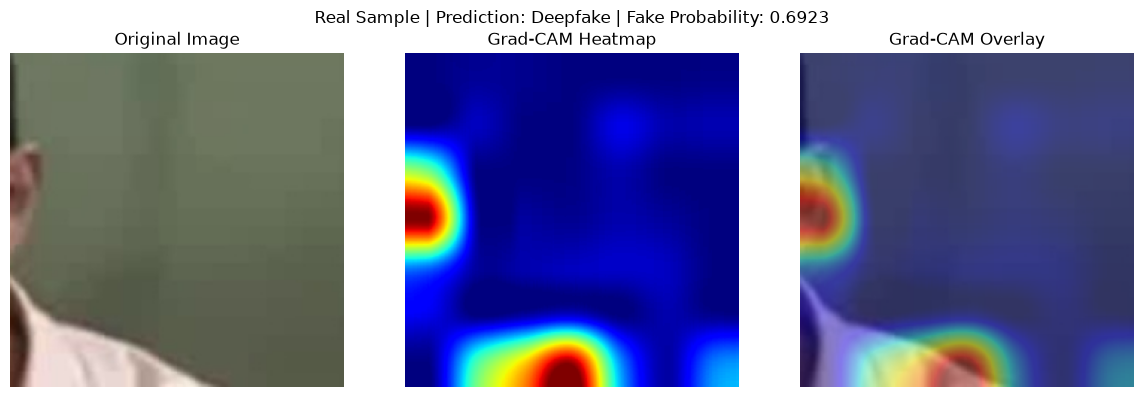

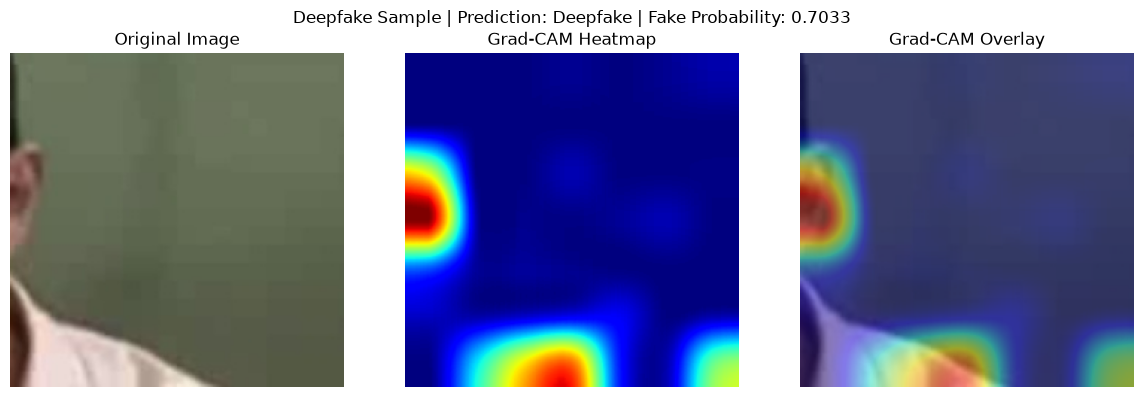

In [8]:
# ============================================================
# CELL 7: VISUALIZE GRAD-CAM HEATMAP OVERLAYS
# ============================================================

def display_gradcam(image, heatmap, title, prediction, probability):

    # Resize heatmap to original image dimensions
    heatmap_resized = Image.fromarray(
        np.uint8(heatmap * 255)
    ).resize(image.size)

    heatmap_resized = np.array(heatmap_resized)

    # Convert original image to NumPy
    original = np.array(image)

    # Plot original and heatmap
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(original)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(heatmap_resized, cmap="jet")
    plt.title("Grad-CAM Heatmap")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(original)
    plt.imshow(
        heatmap_resized,
        cmap="jet",
        alpha=0.45
    )
    plt.title("Grad-CAM Overlay")
    plt.axis("off")

    plt.suptitle(
        f"{title} | Prediction: {prediction} | "
        f"Fake Probability: {probability:.4f}"
    )

    plt.tight_layout()
    plt.show()


# Display Real sample
display_gradcam(
    real_image,
    real_heatmap,
    "Real Sample",
    real_prediction,
    real_probability
)

# Display Deepfake sample
display_gradcam(
    fake_image,
    fake_heatmap,
    "Deepfake Sample",
    fake_prediction,
    fake_probability
)

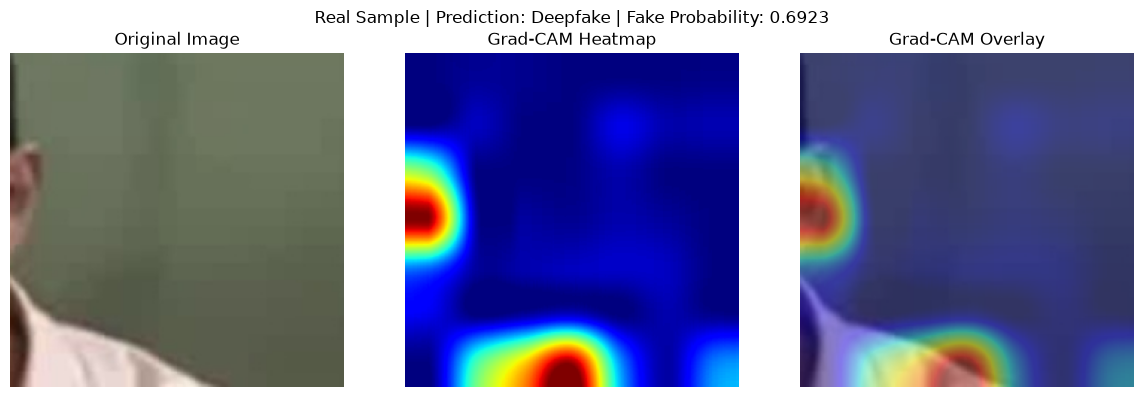

Saved: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\results\week12_gradcam_real.png


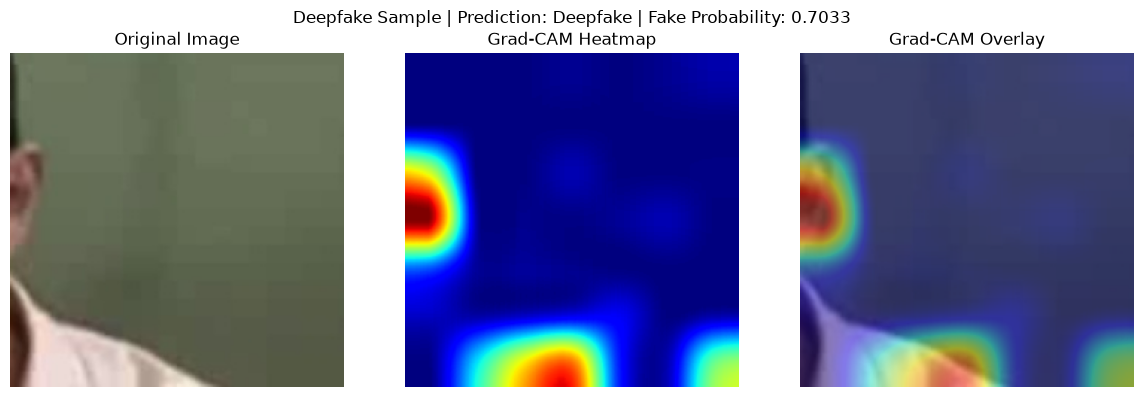

Saved: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\results\week12_gradcam_deepfake.png

Week 12 Grad-CAM visualizations saved successfully!


In [9]:
# ============================================================
# CELL 8: SAVE GRAD-CAM VISUALIZATIONS
# ============================================================

def save_gradcam_result(
    image, heatmap, title, prediction, probability, filename
):

    # Resize heatmap
    heatmap_resized = np.array(
        Image.fromarray(
            np.uint8(heatmap * 255)
        ).resize(image.size)
    )

    original = np.array(image)

    # Create visualization
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    axes[0].imshow(original)
    axes[0].set_title("Original Image")
    axes[0].axis("off")

    axes[1].imshow(heatmap_resized, cmap="jet")
    axes[1].set_title("Grad-CAM Heatmap")
    axes[1].axis("off")

    axes[2].imshow(original)
    axes[2].imshow(
        heatmap_resized,
        cmap="jet",
        alpha=0.45
    )
    axes[2].set_title("Grad-CAM Overlay")
    axes[2].axis("off")

    fig.suptitle(
        f"{title} | Prediction: {prediction} | "
        f"Fake Probability: {probability:.4f}"
    )

    plt.tight_layout()

    save_path = RESULTS_DIR / filename

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Saved:", save_path)


# Save Real sample
save_gradcam_result(
    real_image,
    real_heatmap,
    "Real Sample",
    real_prediction,
    real_probability,
    "week12_gradcam_real.png"
)

# Save Deepfake sample
save_gradcam_result(
    fake_image,
    fake_heatmap,
    "Deepfake Sample",
    fake_prediction,
    fake_probability,
    "week12_gradcam_deepfake.png"
)

print("\nWeek 12 Grad-CAM visualizations saved successfully!")

In [10]:
# ============================================================
# CELL 9: VERIFY AND SAVE WEEK 12 RESULTS
# ============================================================

real_output_path = RESULTS_DIR / "week12_gradcam_real.png"
fake_output_path = RESULTS_DIR / "week12_gradcam_deepfake.png"

# Check saved files
print("GRAD-CAM FILE VERIFICATION")
print("=" * 45)

print("Real Grad-CAM:", real_output_path.exists())
print("Deepfake Grad-CAM:", fake_output_path.exists())

# Prepare explainability summary
explainability_df = pd.DataFrame([
    {
        "Actual_Label": "Real",
        "Predicted_Label": real_prediction,
        "Fake_Probability": real_probability,
        "Correct_Prediction": real_prediction == "Real"
    },
    {
        "Actual_Label": "Deepfake",
        "Predicted_Label": fake_prediction,
        "Fake_Probability": fake_probability,
        "Correct_Prediction": fake_prediction == "Deepfake"
    }
])

print("\nEXPLAINABILITY SUMMARY")
print(explainability_df.to_string(index=False))

# Save summary
explainability_df.to_csv(
    RESULTS_DIR / "week12_explainability_summary.csv",
    index=False
)

print("\nWeek 12 explainability summary saved!")

GRAD-CAM FILE VERIFICATION
Real Grad-CAM: True
Deepfake Grad-CAM: True

EXPLAINABILITY SUMMARY
Actual_Label Predicted_Label  Fake_Probability  Correct_Prediction
        Real        Deepfake          0.692252               False
    Deepfake        Deepfake          0.703307                True

Week 12 explainability summary saved!
